In [171]:
import numpy as np
import seaborn as sns
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import MinMaxScaler
from sklearn.linear_model import LinearRegression

In [172]:
import warnings
warnings.filterwarnings('ignore')

In [173]:
sns.set(rc={'figure.figsize': (8, 6)})

In [174]:
data = pd.read_csv('student-mat.csv')
data

,school,gender,age,address,famsize,Pstatus,Medu,Fedu,Mjob,Fjob,...,higher,internet,romantic,famrel,freetime,goout,health,absences,G1,G3
0,GP,F,18,U,GT3,A,4,4,at_home,teacher,...,yes,no,no,4,3,4,3,6,5,6
1,GP,F,17,U,GT3,T,1,1,at_home,other,...,yes,yes,no,5,3,3,3,4,5,6
2,GP,F,15,U,LE3,T,1,1,at_home,other,...,yes,yes,no,4,3,2,3,10,7,10
3,GP,F,15,U,GT3,T,4,2,health,services,...,yes,yes,yes,3,2,2,5,2,15,15
4,GP,F,16,U,GT3,T,3,3,other,other,...,yes,no,no,4,3,2,5,4,6,10
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
390,MS,M,20,U,LE3,A,2,2,services,services,...,yes,no,no,5,5,4,4,11,9,9
391,MS,M,17,U,LE3,T,3,1,services,services,...,yes,yes,no,2,4,5,2,3,14,16
392,MS,M,21,R,GT3,T,1,1,other,other,...,yes,no,no,5,5,3,3,3,10,7
393,MS,M,18,R,LE3,T,3,2,services,other,...,yes,yes,no,4,4,1,5,0,11,10


<Axes: xlabel='G3', ylabel='Count'>

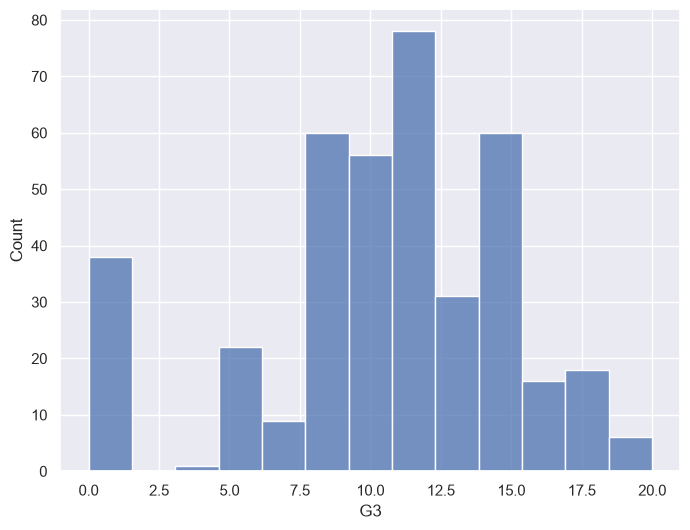

In [175]:
sns.histplot(data['G3'])

In [176]:
data = data[data['G3']!=0]

In [177]:
X = data.drop(columns=['G3'])
y = data['G3']

In [178]:
x_train, x_test, y_train, y_test = train_test_split(X, y, test_size=50, random_state=0)

In [179]:
Xy_train = x_train.copy(deep=True)
Xy_train['y'] = y_train

In [180]:
Xy_train.corr(numeric_only=True)

,age,Medu,Fedu,traveltime,studytime,failures,famrel,freetime,goout,health,absences,G1,y
age,1.000000,-0.143667,-0.152028,0.124947,-0.012044,0.265867,0.105719,0.018381,0.127471,-0.066960,0.232719,-0.058061,-0.163554
Medu,-0.143667,1.000000,0.622469,-0.189125,0.059405,-0.217911,-0.005481,-0.021037,0.080858,-0.030022,0.052977,0.180870,0.205427
Fedu,-0.152028,0.622469,1.000000,-0.194381,-0.031392,-0.265805,-0.031753,-0.054498,0.029325,-0.007715,-0.015996,0.160996,0.150231
traveltime,0.124947,-0.189125,-0.194381,1.000000,-0.105084,0.131414,-0.002823,-0.007708,0.062239,0.016959,0.028547,-0.119743,-0.131757
studytime,-0.012044,0.059405,-0.031392,-0.105084,1.000000,-0.136720,0.063829,-0.132218,-0.018720,-0.087165,-0.098216,0.156326,0.158553
failures,0.265867,-0.217911,-0.265805,0.131414,-0.136720,1.000000,-0.020901,0.133293,0.195804,0.042964,0.161519,-0.326272,-0.311091
famrel,0.105719,-0.005481,-0.031753,-0.002823,0.063829,-0.020901,1.000000,0.183048,0.068130,0.140506,-0.073748,0.052678,0.075401
freetime,0.018381,-0.021037,-0.054498,-0.007708,-0.132218,0.133293,0.183048,1.000000,0.255339,0.086641,-0.074686,-0.023542,-0.051553
goout,0.127471,0.080858,0.029325,0.062239,-0.018720,0.195804,0.068130,0.255339,1.000000,-0.061314,0.057467,-0.170340,-0.196119
health,-0.066960,-0.030022,-0.007715,0.016959,-0.087165,0.042964,0.140506,0.086641,-0.061314,1.000000,-0.057903,-0.074392,-0.071237


In [181]:
corr = Xy_train.corr(numeric_only=True)['y']

In [182]:
corr = corr[(corr >= 0.1) | (corr <= -0.1)]

In [183]:
corr

age          -0.163554
Medu          0.205427
Fedu          0.150231
traveltime   -0.131757
studytime     0.158553
failures     -0.311091
goout        -0.196119
absences     -0.229859
G1            0.896589
y             1.000000
Name: y, dtype: float64

<Axes: xlabel='G1', ylabel='y'>

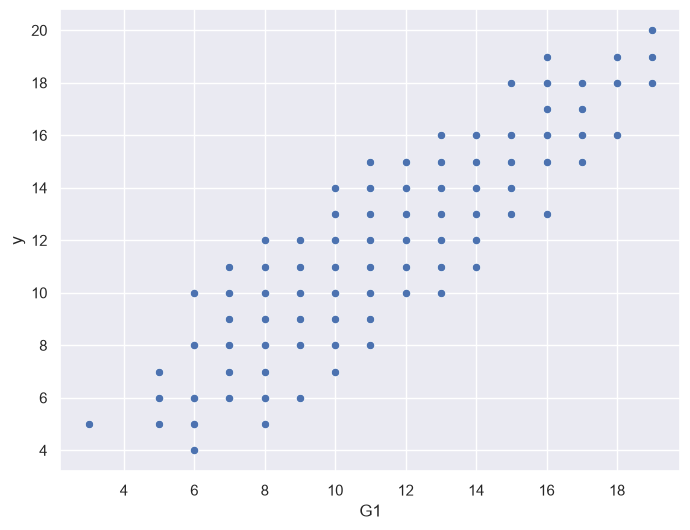

In [184]:
sns.scatterplot(x=Xy_train['G1'], y=Xy_train['y'])

<Axes: xlabel='age', ylabel='y'>

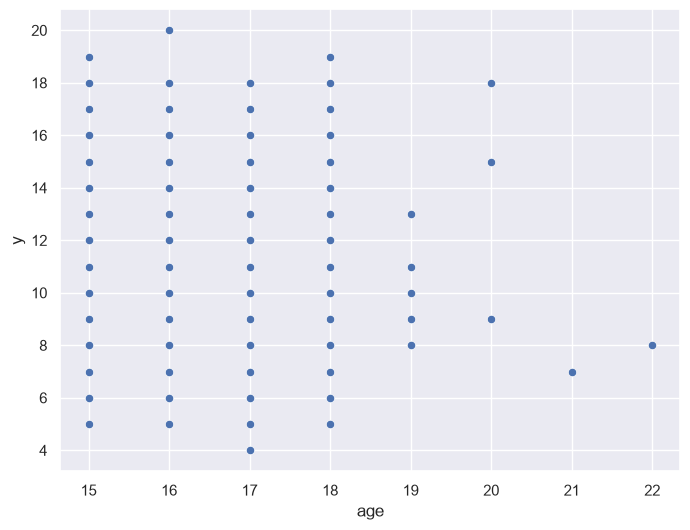

In [185]:
sns.scatterplot(x=Xy_train['age'], y=Xy_train['y'])

<Axes: xlabel='age', ylabel='y'>

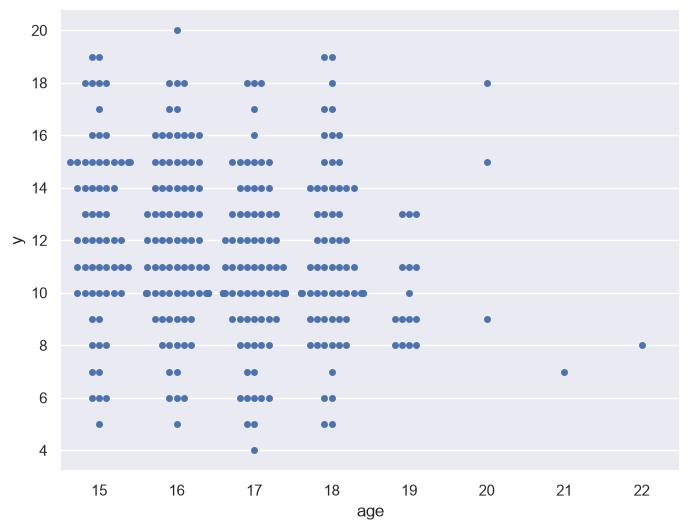

In [186]:
sns.swarmplot(x=Xy_train['age'], y=Xy_train['y'])

In [187]:
cat_cols = ['higher', 'gender', 'address', 'famsize', 'Pstatus', 'Mjob', 'Fjob', 'reason', 'guardian', 'schoolsup', 'school', 'famsup', 'paid', 'activities', 'nursery', 'internet', 'romantic']

for col in cat_cols:
    print(Xy_train.groupby(col, as_index=False).agg({'y': 'mean'}))
    print('___')

  higher          y
0     no   9.833333
1    yes  11.657627
___
  gender          y
0      F  11.238994
1      M  11.959459
___
  address          y
0       R  10.771429
1       U  11.827004
___
  famsize          y
0     GT3  11.479638
1     LE3  11.860465
___
  Pstatus          y
0       A  11.968750
1       T  11.541818
___
       Mjob          y
0   at_home  10.622222
1    health  13.583333
2     other  10.962963
3  services  12.253012
4   teacher  11.744681
___
       Fjob          y
0   at_home  11.714286
1    health  11.866667
2     other  11.339181
3  services  11.476190
4   teacher  13.565217
___
       reason          y
0      course  11.279279
1        home  11.583333
2       other  11.928571
3  reputation  11.880952
___
  guardian          y
0   father  11.813333
1   mother  11.602871
2    other  10.695652
___
  schoolsup          y
0        no  11.835821
1       yes   9.871795
___
  school          y
0     GP  11.715356
1     MS  10.725000
___
  famsup          y
0     no 

In [188]:
numeric_factors_to_use = ['age', 'traveltime', 'G1', 'studytime', 'Medu', 'Fedu', 'failures']
categorical_columns = ['Mjob', 'address', 'higher']

In [189]:
Xy_train.groupby('higher', as_index=False).agg({'y':'mean'})

,higher,y
0,no,9.833333
1,yes,11.657627


In [190]:
from category_encoders.target_encoder import TargetEncoder

In [191]:
mjob_target_encoder = TargetEncoder()
mjob_target_encoder.fit(Xy_train['Mjob'], Xy_train['y'])

address_target_encoder = TargetEncoder()
address_target_encoder.fit(Xy_train['address'], Xy_train['y'])

higher_target_encoder = TargetEncoder()
higher_target_encoder.fit(Xy_train['higher'], Xy_train['y'])

,cols,['higher']
,verbose,0
,drop_invariant,False
,return_df,True
,handle_missing,'value'
,handle_unknown,'value'
,min_samples_leaf,20
,smoothing,10
,hierarchy,None
,min_group_size,None
,min_group_name,None


In [192]:
# 1. Применяем обученные энкодеры к train и сразу к test
Xy_train['Mjob_encoded'] = mjob_target_encoder.transform(Xy_train['Mjob'])
Xy_train['address_encoded'] = address_target_encoder.transform(Xy_train['address'])
Xy_train['higher_encoded'] = higher_target_encoder.transform(Xy_train['higher'])

x_test['Mjob_encoded'] = mjob_target_encoder.transform(x_test['Mjob'])
x_test['address_encoded'] = address_target_encoder.transform(x_test['address'])
x_test['higher_encoded'] = higher_target_encoder.transform(x_test['higher'])

In [193]:
numeric_factors_to_use = ['age', 'traveltime', 'G1', 'studytime', 'Medu', 'Fedu', 'failures', 'goout', 'absences']
encoded_categorical_columns = ['Mjob_encoded', 'address_encoded', 'higher_encoded']

factors_to_use = numeric_factors_to_use + encoded_categorical_columns

X_train_encoded = Xy_train[factors_to_use].copy()
X_test_encoded = x_test[factors_to_use].copy()

In [195]:
scaler = MinMaxScaler()
scaler.fit(X_train_encoded)

X_train_scaled = scaler.transform(X_train_encoded)
X_test_scaled = scaler.transform(X_test_encoded)

In [196]:
model = LinearRegression()
model.fit(X_train_scaled, y_train)

model.score(X_train_scaled, y_train)

0.8299803518966968

In [197]:
from sklearn.metrics import mean_absolute_error, r2_score

y_pred = model.predict(X_test_scaled)

mae = mean_absolute_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)

print('MAE:', mae)
print('R2:', r2)

MAE: 1.2468414396780503
R2: 0.7433498479841913


95% доверительный интервал: [1.0279880202275593; 1.4764719753281934]


<Axes: ylabel='Count'>

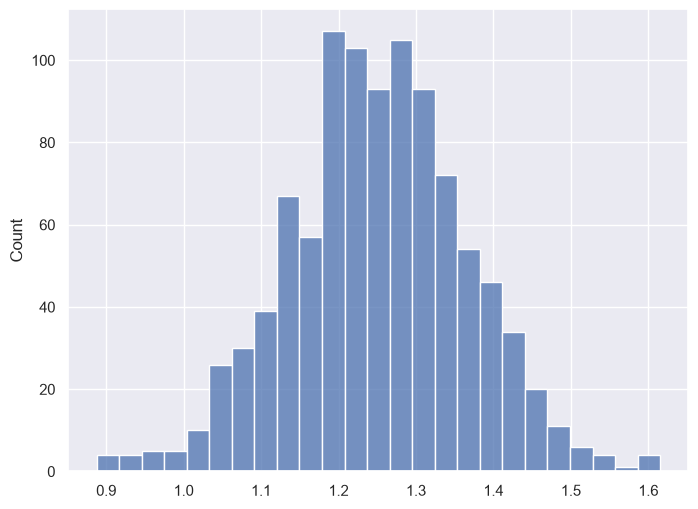

In [200]:
test_df = pd.DataFrame({'y_true': y_test, 'y_pred': y_pred})

mae_list = []

for i in range(1000):
    sample_df = test_df.sample(n=len(test_df), replace=True, random_state=i)
    score = mean_absolute_error(sample_df['y_true'], sample_df['y_pred'])
    mae_list.append(score)

left = np.percentile(mae_list, 2.5)
right = np.percentile(mae_list, 97.5)

print(f'95% доверительный интервал: [{left}; {right}]')

sns.histplot(mae_list)

In [203]:
weights = pd.DataFrame({'Признак': factors_to_use, 'Вес': model.coef_})

weights

,Признак,Вес
0,age,-1.514368
1,traveltime,0.019387
2,G1,13.861943
3,studytime,0.176410
4,Medu,0.670034
5,Fedu,-0.482941
6,failures,0.236092
7,goout,-0.516779
8,absences,-2.752921
9,Mjob_encoded,0.347868


Ключевым положительным фактором, определяющим итоговую оценку, является оценка за первый учебный период G1 (вес 13.86). Ученики, хорошо учащиеся в начале года, с высокой вероятностью сохраняют высокий результат. Сильнее всего итоговый балл снижают большое количество пропусков занятий absences (вес -2.75) и более старший возраст ученика age (вес -1.51). Остальные признаки: время в пути до школы traveltime (0.02), время на самостоятельную учёбу studytime (0.18), место жительства address_encoded (0.22), получили веса, близкие к нулю, и практически не влияют на предсказание.